# PathFM-Chaotic: forecasts and long rollouts

Generate short forecasts, visualize 4,096-step sample paths, and reproduce the release's PANDA accuracy protocol.
Both chaotic models default to 16 sample paths with 10-step Euler sampling.

From the PathFM folder:

```bash
pip install ".[benchmarks,notebooks]"
jupyter lab notebooks/chaotic_forecasting.ipynb
```

The example uses the paper's Rössler trajectory, with 512 observed steps and a full 4,096-step continuation bundled in [data/rossler-paper.npz](data/rossler-paper.npz).
Model weights can come from the sibling `huggingface/` folder or Hugging Face.

| Model | Default decoder |
|---|---|
| [PathFM-Chaotic-75M](https://huggingface.co/autogluon/pathfm-chaotic-75m) | 10-step Euler |
| [PathFM-Chaotic-125M](https://huggingface.co/autogluon/pathfm-chaotic-125m) | 10-step Euler |


In [1]:
from pathlib import Path

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from pathfm import PathFMPipeline
from pathfm.benchmarks.panda import window_smape

ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "pyproject.toml").is_file() and (p / "src" / "pathfm").is_dir()
)
MODEL_NAME = "pathfm-chaotic-125m"  # Choose any model from the table above.
LOCAL_MODEL = ROOT.parent / "huggingface" / MODEL_NAME
MODEL = str(LOCAL_MODEL) if LOCAL_MODEL.is_dir() else f"autogluon/{MODEL_NAME}"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
EXAMPLE_PATH = ROOT / "notebooks" / "data" / "rossler-paper.npz"
OUTPUT_DIR = ROOT / "outputs" / "chaotic-demo"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

model = PathFMPipeline.from_pretrained(MODEL, device=DEVICE)
print(f"{MODEL_NAME}: {DEVICE}, {model.num_samples} paths, {model.ode_steps} {model.sampler_method} steps")

/opt/pytorch/lib64/python3.12/site-packages/torch/cuda/__init__.py:63: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


pathfm-chaotic-125m: cpu, 16 paths, 10 euler steps


## Load an observed history

Inputs use `[batch, channels, context]`.
Use `np.load("context.npy", allow_pickle=False)` to read your own observations, adding a batch dimension if needed.
The comparison plots additionally require a held-out `truth` continuation.
Rollouts require finite observations and return forecasts in the input units.

This example uses the same Rössler trajectory and forecast origin as the paper's appendix figure: trajectory 9, origin 512.
The bundled file supplies the exact 512-step context and all 4,096 observed future steps.
The phase portrait uses channels 0 and 1 (x–y), matching the paper.
See [the data provenance](data/README.md) for the source.

In [2]:
with np.load(EXAMPLE_PATH, allow_pickle=False) as example:
    context = example["context"][None].copy()
    truth = example["truth"].copy()
    SYSTEM = example["system"].item()
    TRAJECTORY = int(example["trajectory_index"])
    ORIGIN = int(example["forecast_origin"])
    PHASE_CHANNELS = tuple(example["phase_channels"].tolist())
print(f"{SYSTEM}: paper trajectory {TRAJECTORY}, forecast origin {ORIGIN}")
print("Input:", context.shape, "| Observed continuation:", truth.shape)

Rossler: paper trajectory 9, forecast origin 512
Input: (1, 3, 512) | Observed continuation: (3, 4096)


## Short forecasts: samples and quantiles

`predict_samples` returns one tensor shaped `[channels, paths, horizon]` per batch item.
`predict_quantiles` returns `[channels, horizon, quantiles]` and a point forecast per item.
Both calls below forecast one 256-step native block.

In [3]:
model.set_stream(0)
short_samples = model.predict_samples(context, prediction_length=256)[0].numpy()
model.set_stream(0)
quantiles, point_forecasts = model.predict_quantiles(
    context, prediction_length=256, quantile_levels=[0.1, 0.5, 0.9],
)
short_quantiles = quantiles[0].numpy()
point = point_forecasts[0].numpy()
print("Samples:", short_samples.shape, "| Quantiles:", short_quantiles.shape)

Samples: (3, 16, 256) | Quantiles: (3, 256, 3)


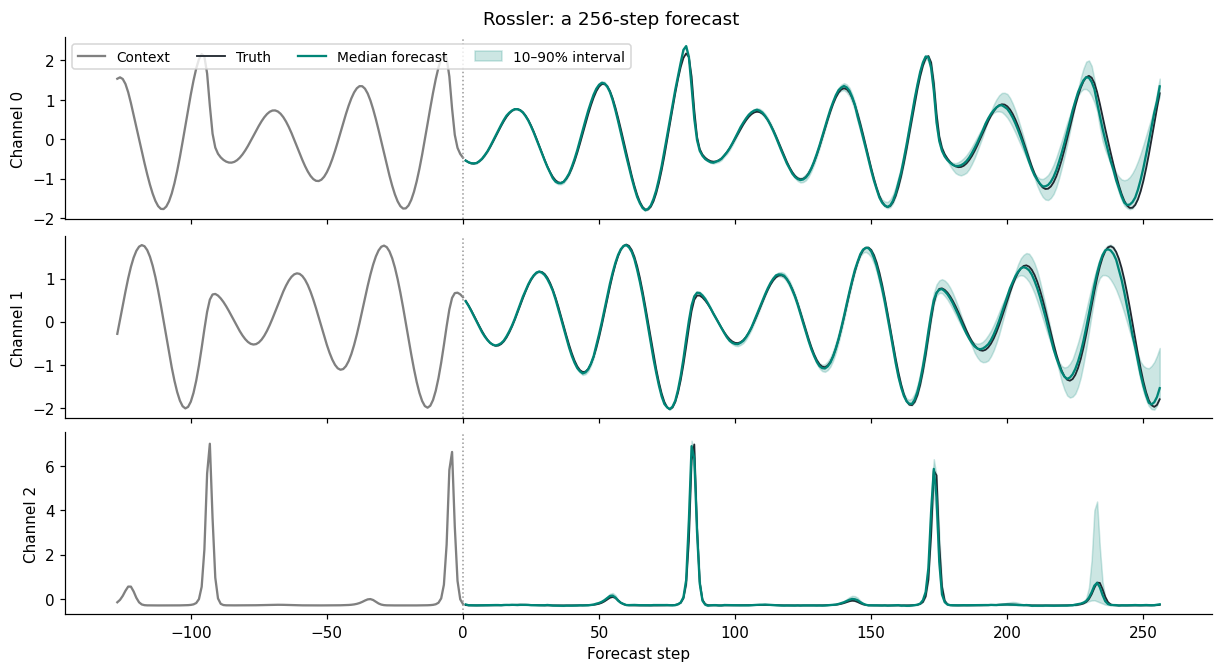

In [4]:
fig, axes = plt.subplots(context.shape[1], 1, figsize=(11, 6), sharex=True, layout="constrained")
steps = np.arange(1, 257)
for channel, ax in enumerate(np.atleast_1d(axes)):
    ax.plot(np.arange(-127, 1), context[0, channel, -128:], color="0.5", label="Context")
    ax.plot(steps, truth[channel, :256], color="#202830", linewidth=1.2, label="Truth")
    ax.plot(steps, short_quantiles[channel, :, 1], color="#008577", label="Median forecast")
    ax.fill_between(
        steps, short_quantiles[channel, :, 0], short_quantiles[channel, :, 2],
        color="#008577", alpha=0.2, label="10–90% interval",
    )
    ax.axvline(0, color="0.6", linestyle=":", linewidth=1)
    ax.set_ylabel(f"Channel {channel}")
axes[0].legend(ncol=4, fontsize=9)
axes[-1].set_xlabel("Forecast step")
fig.suptitle(f"{SYSTEM}: a 256-step forecast")
fig.savefig(OUTPUT_DIR / "short_forecast.png", dpi=160)
plt.show()

## Continue independent paths for 4,096 steps

`rollout` continues each sampled path using that path's own recent history.
It returns `[batch, paths, channels, horizon]`.
Quantile bands in a plot summarize the ensemble; they are not fed back into the model.

In [5]:
HORIZON = 4096
forecast = model.rollout(context, prediction_length=HORIZON, num_samples=16, seed=SEED)
paths = forecast.samples[0].numpy()
first_invalid = forecast.first_invalid_step[0].numpy()
valid = first_invalid == HORIZON
print("Rollouts:", paths.shape)
print(f"Paths valid through all {HORIZON} steps: {valid.sum()}/{len(valid)}")

np.savez_compressed(
    OUTPUT_DIR / "rollout.npz",
    context=context, truth=truth, samples=forecast.samples.numpy(),
    first_invalid_step=forecast.first_invalid_step.numpy(),
)

Rollouts: (16, 3, 4096)
Paths valid through all 4096 steps: 16/16


`first_invalid_step` equals the requested horizon for a fully valid path.
If a path becomes invalid, its returned values freeze after its last valid state.
The plots below mask that frozen tail so it is not presented as a successful continuation.

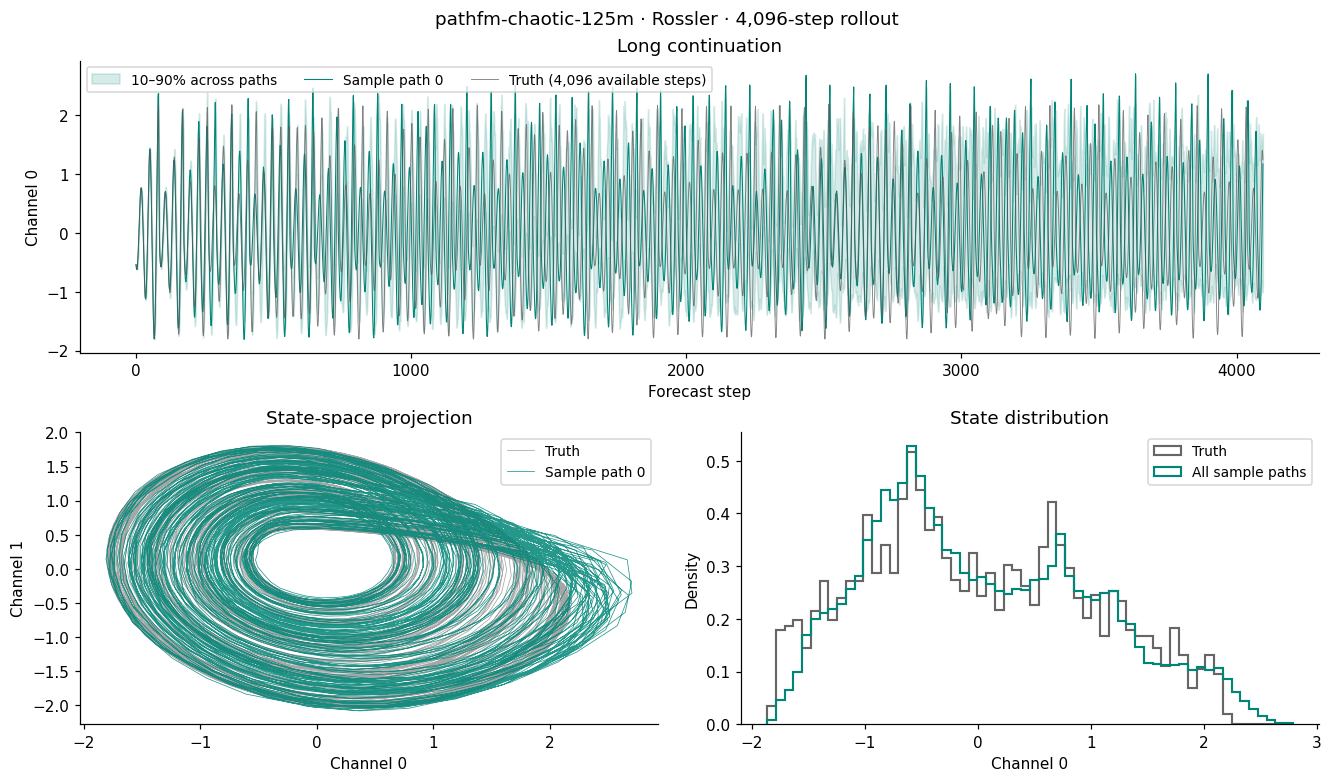

In [6]:
plotted = paths.copy()
for index, stop in enumerate(first_invalid):
    plotted[index, :, int(stop):] = np.nan
lower, upper = np.nanquantile(plotted, [0.1, 0.9], axis=0)

def plot_long_rollout(path_index=0, channel=0):
    fig = plt.figure(figsize=(12, 7), layout="constrained")
    grid = fig.add_gridspec(2, 2)
    ax_time = fig.add_subplot(grid[0, :])
    ax_phase = fig.add_subplot(grid[1, 0])
    ax_density = fig.add_subplot(grid[1, 1])
    steps = np.arange(1, HORIZON + 1)
    ax_time.fill_between(steps, lower[channel], upper[channel], color="#008577", alpha=0.16, label="10–90% across paths")
    ax_time.plot(steps, plotted[path_index, channel], color="#008577", linewidth=0.7, label=f"Sample path {path_index}")
    ax_time.plot(np.arange(1, truth.shape[1] + 1), truth[channel], color="0.35", linewidth=0.6, alpha=0.75, label=f"Truth ({truth.shape[1]:,} available steps)")
    ax_time.set(xlabel="Forecast step", ylabel=f"Channel {channel}", title="Long continuation")
    ax_time.legend(ncol=3, fontsize=9)

    phase_x, phase_y = PHASE_CHANNELS
    ax_phase.plot(truth[phase_x], truth[phase_y], color="0.65", linewidth=0.5, label="Truth")
    ax_phase.plot(plotted[path_index, phase_x], plotted[path_index, phase_y], color="#008577", linewidth=0.5, alpha=0.85, label=f"Sample path {path_index}")
    ax_phase.set(xlabel=f"Channel {phase_x}", ylabel=f"Channel {phase_y}", title="State-space projection")
    ax_phase.legend(fontsize=9)

    sample_states = plotted[:, channel].ravel()
    sample_states = sample_states[np.isfinite(sample_states)]
    bins = np.histogram_bin_edges(np.concatenate([truth[channel], sample_states]), bins=60)
    ax_density.hist(truth[channel], bins=bins, density=True, histtype="step", color="0.4", linewidth=1.4, label="Truth")
    ax_density.hist(sample_states, bins=bins, density=True, histtype="step", color="#008577", linewidth=1.4, label="All sample paths")
    ax_density.set(xlabel=f"Channel {channel}", ylabel="Density", title="State distribution")
    ax_density.legend(fontsize=9)
    fig.suptitle(f"{MODEL_NAME} · {SYSTEM} · {HORIZON:,}-step rollout")
    return fig

fig = plot_long_rollout(path_index=0, channel=0)
fig.savefig(OUTPUT_DIR / "long_rollouts.png", dpi=160)
plt.show()

### Explore individual paths

Change the sample path or channel to inspect different continuations.
The static figure above remains visible when viewing this notebook without a running kernel.

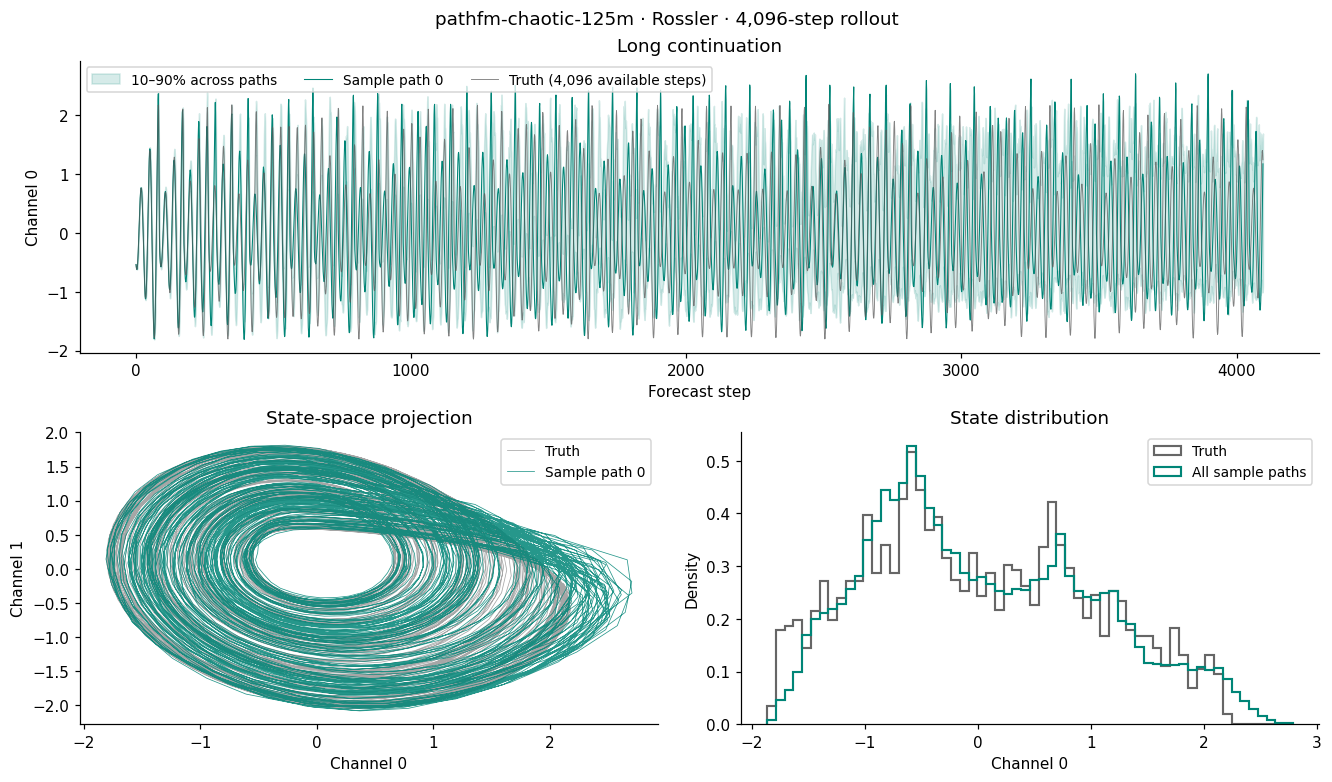

In [7]:
path_control = widgets.IntSlider(min=0, max=len(paths) - 1, value=0, description="Path")
channel_control = widgets.IntSlider(min=0, max=paths.shape[1] - 1, value=0, description="Channel")
display(widgets.HBox([path_control, channel_control]))
interactive_figure = plot_long_rollout()
plot_display = display(interactive_figure, display_id=True)
plt.close(interactive_figure)

def update_plot(change):
    figure = plot_long_rollout(path_control.value, channel_control.value)
    plot_display.update(figure)
    plt.close(figure)

path_control.observe(update_plot, names="value")
channel_control.observe(update_plot, names="value")

## Short-horizon accuracy

PANDA scores errors after standardizing forecasts and truth with the observed context's per-channel mean and standard deviation.
Its sMAPE uses `100 * abs(prediction - truth) / (abs(prediction) + abs(truth) + 1e-10)`.
Here are the scores for this one example window; the full benchmark uses the fixed windows and sampling settings in the command below.

In [8]:
example_scores = window_smape(point[None], truth[None, :, :256], context)
display(pd.DataFrame({
    "Horizon": [64, 128, 256],
    "Example sMAPE ↓": [float(example_scores[f"h{h}_smape"][0]) for h in (64, 128, 256)],
}).style.format({"Example sMAPE ↓": "{:.4f}"}).hide(axis="index"))

Horizon,Example sMAPE ↓
64,6.8743
128,7.1618
256,8.8138


### Reproduce the released benchmark

The preparer downloads pinned `base40` and `skew40` test splits and creates the original 56,082 windows: six per trajectory across 9,347 trajectories in 480 source groups.
Each window has 512 observed steps.
The evaluator uses 16 stratified paths, 10-step Euler sampling, the average of the two middle paths as the coordinate median, and the archived seed and batching order.
It reports only 64/128/256-step accuracy; long rollouts above remain sample-based.

Run these commands from the PathFM folder:

```bash
pip install -r requirements.txt
python -m pathfm.benchmarks.download panda --output datasets/panda
python -m pathfm.benchmarks.panda \
  --model autogluon/pathfm-chaotic-125m --data-root datasets/panda \
  --output outputs/panda-125m --device cuda
```

Use any chaotic model ID from the table above, with a separate output directory for each model.
For a quick check, append `--max-groups 1` and use a separate output directory.
That check evaluates the first complete source group for each channel count.

The full command writes `groups.csv` and `summary.json`.
Scores average windows within each trajectory, trajectories within each source group, then equally weight all 480 source groups.

| Model | sMAPE@64 ↓ | sMAPE@128 ↓ | sMAPE@256 ↓ |
|---|---:|---:|---:|
| PathFM-Chaotic-75M | 16.9402 | 22.1646 | 28.2200 |
| PathFM-Chaotic-125M | 16.4464 | 21.5160 | 27.4294 |

The protocol follows the pinned [PANDA evaluator](https://github.com/abao1999/panda/tree/4764e0556105979a5b08ef97fd7533726d0562ac), with the release's mean across source groups.